<a href="https://colab.research.google.com/github/kinjaljoshi/mech-interp-from-scratch/blob/master/probes_in_mlp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Forward Hook
A forward hook is a function PyTorch calls every time a module runs, handing it that module’s output. It lets us record activations without changing the model. The recipe is always the same three parts:
1. define a hook that stores output.detach()
2.  register it
3. remove it afterward.

In [2]:
import torch, torch.nn as nn, torch.nn.functional as F

toy = nn.Sequential(nn.Linear(3, 2) , nn.ReLU(), nn.Linear(2, 1))

captured = {}

#1. define the hook
def hook(model, input, output):
    captured["relu_in"] = input[0].detach()
    captured["relu_out"] = output.detach()

#2. register hook
handle1 = toy[0].register_forward_hook(hook)
handle = toy[1].register_forward_hook(hook)

x = torch.randn([4, 3])
y = toy(x)
#3. remove the hook
handle.remove()

print("captured in \n", captured["relu_in"])
print("captured out \n", captured["relu_out"])

#manual verification

yhat = torch.relu(x @ toy[0].weight.T + toy[0].bias)

print("manual capture \n", yhat)
assert torch.allclose(captured["relu_out"], yhat)

captured in 
 tensor([[ 0.2080,  0.7362],
        [-0.1012,  0.7927],
        [-0.4861,  0.2083],
        [-0.9739,  0.3046]])
captured out 
 tensor([[0.2080, 0.7362],
        [0.0000, 0.7927],
        [0.0000, 0.2083],
        [0.0000, 0.3046]])
manual capture 
 tensor([[0.2080, 0.7362],
        [0.0000, 0.7927],
        [0.0000, 0.2083],
        [0.0000, 0.3046]], grad_fn=<ReluBackward0>)


#Baseline MLP for MINST

In [3]:
class MLP(nn.Module):
  def __init__(self):
    super().__init__()
    self.net = nn.Sequential(nn.Linear(784, 256),
                             nn.ReLU(),
                             nn.Linear(256, 128),
                             nn.ReLU(),
                             nn.Linear(128, 10))
  def forward(self, x):
    return self.net(x)

In [4]:
def train_classifier(model, X, Y, batch_size = 256, epochs = 5, lr= 1e-3):
  opt = torch.optim.Adam(model.parameters(), lr= lr)
  for _ in range(epochs):
    perm = torch.randperm(X.shape[0])
    for n in range(0, X.shape[0], batch_size):
      idx = perm[n:n + batch_size]
      ypred = model(X[idx])
      loss = F.cross_entropy(ypred, Y[idx])
      #3 training steps
      opt.zero_grad()
      loss.backward()
      opt.step()

def get_model_activations(model, x):
  acts, handle = {}, []
  print("getting activations")
  def make_hook(name):
    def hook(module, input, output):
      print("capturing activations")
      acts[name] = output.detach()
    return hook

  print("registering hooks")
  handle.append(model.net[1].register_forward_hook(make_hook("layer_1")))
  handle.append(model.net[3].register_forward_hook(make_hook("layer_2")))
  handle.append(model.net[4].register_forward_hook(make_hook("logits")))
  #invoke model to capture activations
  with torch.no_grad():
      model(x)
  #remove hooks
  for h in handle:
      h.remove()
  acts["pixel"] = x
  return acts



In [5]:
#get training and testing datasets
import torchvision, torchvision.datasets as datasets

train_ds = datasets.MNIST("data", train=True, download=True)
test_ds = datasets.MNIST("data", train=False, download=True)

Xtrain = train_ds.data.float().div(255).view(-1, 28*28)
Ytrain = train_ds.targets
Xtest = test_ds.data.float().div(255).view(-1, 28*28)
Ytest = test_ds.targets

100%|██████████| 9.91M/9.91M [00:00<00:00, 64.6MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.56MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 15.1MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 3.04MB/s]


In [6]:
print(Xtrain.shape, Ytrain.shape, Xtest.shape, Ytest.shape)

torch.Size([60000, 784]) torch.Size([60000]) torch.Size([10000, 784]) torch.Size([10000])


In [7]:
torch.manual_seed(0)
mlp = MLP()
train_classifier(mlp, Xtrain, Ytrain)

In [9]:
#getting accuracy
with torch.no_grad():
  test_out = mlp(Xtest)
  print(test_out)
  print(test_out.shape)
  print(f"results - {test_out.argmax(dim=1)}")
  print(f"Actual results - {Ytest}")
  print(f"accuracy - {round((test_out.argmax(dim=1) == Ytest).float().mean().item(),2)}")

tensor([[ -3.9587,  -2.8858,   2.0968,  ...,  10.6002,   0.0191,  -0.4629],
        [ -2.2132,   3.5268,  10.3972,  ...,  -9.7463,  -0.4599, -12.5039],
        [ -4.9696,   6.1506,  -1.0427,  ...,   0.4180,   0.2602,  -3.4617],
        ...,
        [ -8.6535,  -5.6335,  -8.7855,  ...,   2.3967,   2.4531,   4.5111],
        [ -4.3921,  -3.4621,  -6.7565,  ...,  -6.9103,   3.9205,  -5.7124],
        [ -0.1212,  -8.0264,  -0.5195,  ..., -12.6721,  -2.5124,  -7.5147]])
torch.Size([10000, 10])
results - tensor([7, 2, 1,  ..., 4, 5, 6])
Actual results - tensor([7, 2, 1,  ..., 4, 5, 6])
accuracy - 0.97


#Getting training and testing activations

In [10]:
act_training = get_model_activations(mlp, Xtrain)
act_testing = get_model_activations(mlp, Xtest)
for name in ["pixel", "layer_1", "layer_2", "logits"]:
  print(f"{name:>7}: train{tuple(act_training[name].shape)} | test{tuple(act_testing[name].shape)}")

getting activations
registering hooks
capturing activations
capturing activations
capturing activations
getting activations
registering hooks
capturing activations
capturing activations
capturing activations
  pixel: train(60000, 784) | test(10000, 784)
layer_1: train(60000, 256) | test(10000, 256)
layer_2: train(60000, 128) | test(10000, 128)
 logits: train(60000, 10) | test(10000, 10)


In [11]:
#verify that hook recorded true layers
with torch.no_grad():
  layer1_output = torch.relu(mlp.net[0](Xtest))
  print(f"layer1 activation match - {torch.allclose(act_testing['layer_1'], layer1_output)}")

layer1 activation match - True


#Gradient-trained probe
A linear probe is a single linear layer trained to predict a label from a layer’s activations: logits = A @ W + b, with cross-entropy loss.

The network itself is frozen, and only the probe learns. If the probe scores well on held-out data, the label is linearly readable at that layer.

Three things:

1. Train the probe on train activations and score it on test activations. A probe with enough parameters can memorize, so a train score alone proves little.
2. Readable is not the same as used. The probe shows the information is present in a form a linear map can extract. It does not show the network relies on it.
3. Failure is ambiguous. A low score means the information isn’t linearly readable. It might still be there in a nonlinear form.

In [12]:
import torch, torch.nn as nn, torch.nn.functional as F

def training_probe(A, y, n_classes, batch_size = 256, epochs = 200, lr= 1e-3):
  torch.manual_seed(0)
  mu, sd = A.mean(dim =0, keepdim =True), A.std(dim =0, keepdim =True) + 1e-6
  An = (A - mu) / sd # Normalized A
  probe = nn.Linear(An.shape[1], n_classes)
  opt = torch.optim.Adam(probe.parameters(), lr=lr)
  for _ in range(epochs):
    perm = torch.randperm(An.shape[0])
    for n in range(0, An.shape[0], batch_size):
      idx = perm[n: n + batch_size]
      loss = F.cross_entropy(probe(An[idx]), y[idx])
      opt.zero_grad()
      loss.backward()
      opt.step()
  probe.mu , probe.sd = mu, sd  #same sclaing to be used in text
  return probe

@torch.no_grad()
def probe_accuracy(probe, A, Y):
  return (probe((A - probe.mu)/ probe.sd).argmax(dim=1) == Y).float().mean().item()





In [13]:
# Dataset 1: three separated blobs (linearly separable) -> expect near 100%
torch.manual_seed(0)
centers = torch.tensor([[0., 4.], [4., -2.], [-4., -2.]])                 # (3, 2)
print(centers.shape)
yb = torch.randint(0, 3, (3000, ))
Ab = centers[yb] + torch.randn(3000, 2)
print(Ab.shape)

torch.Size([3, 2])
torch.Size([3000, 2])


In [14]:
# Dataset 2: XOR (label = sign(x) * sign(y)) -> information is there, but not linearly readable
Ax = torch.randn(3000 , 2)
yx = ( (Ax[:, 0] > 0)  == (Ax[:, 1] > 0) ).long()

In [15]:
probe_b = training_probe(Ab[:2000], yb[:2000], 3)
probe_x = training_probe(Ax[:2000], yx[:2000], 2)

In [16]:
#get accuracy of probe for both datasets
accuracy_probe_b = probe_accuracy(probe_b, Ab[2000:],yb[2000:])
accuracy_probe_x = probe_accuracy(probe_x, Ax[2000:], yx[2000:])

print(f" probe accuracy for dataset 1 - {accuracy_probe_b}")
print(f" probe accuracy for dataset 2 - {accuracy_probe_x}")


 probe accuracy for dataset 1 - 0.996999979019165
 probe accuracy for dataset 2 - 0.5569999814033508


#Train probe on activations

In [17]:
layers = ["pixel", "layer_1", "layer_2", "logits"]
gd_result = {}
for name in layers:
  probe = training_probe(act_training[name], Ytrain, 10)
  gd_result[name] = (probe_accuracy(probe, act_training[name], Ytrain),
                     probe_accuracy(probe, act_testing[name], Ytest))
  print(f"{name:>7}: dim {act_training[name].shape[1]:>3} | probe train {gd_result[name][0]:.3f} | probe test {gd_result[name][1]:.3f}")


  pixel: dim 784 | probe train 0.943 | probe test 0.921
layer_1: dim 256 | probe train 0.995 | probe test 0.978
layer_2: dim 128 | probe train 0.990 | probe test 0.979
 logits: dim  10 | probe train 0.987 | probe test 0.978


#Closed-form least-squares probe

Last step we found the probe weights by gradient descent. A linear probe can also be solved in one shot. Treat the one-hot labels Y (N × 10) as regression targets and minimize ‖AW − Y‖². Setting the gradient to zero gives the normal equations:

W = (AᵀA)⁻¹ AᵀY

We then predict the class with the largest entry in AW.

1. No training budget. There are no epochs, learning rate or convergence to worry about, which makes this a clean check on whether the gradient probe was undertrained.
2. It optimizes a different objective. Squared error on one-hot targets is not cross-entropy, and it doesn’t directly optimize accuracy.
3. AᵀA can be singular. Raw pixels include columns that are always zero, and layer 1 may contain dead ReLU units, so a plain inverse can fail or blow up.
A small ridge term fixes this: W = (AᵀA + λI)⁻¹ AᵀY. We also solve with torch.linalg.solve rather than forming an explicit inverse, and use float64 because the normal equations square the condition number.
4. Column space. The predictions AW are the projection of Y onto the span of A’s columns.

In [19]:
A = torch.randn(5000, 5, dtype = torch.float64)
W_true = torch.randn(5, 4, dtype = torch.float64)

Y = A @ W_true

W_hat = torch.linalg.solve(A.T @ A, A.T @ Y)
W_lestsq = torch.linalg.lstsq(A, Y).solution
print(f"Learned versus calculated - {torch.allclose(W_true, W_hat)}")
print(f"Learned versus library calculated - {torch.allclose(W_true, W_lestsq)}")

Learned versus calculated - True
Learned versus library calculated - True


In [20]:
# The probe: standardize, add a bias column, ridge-regularized normal equations
def fit_leastsq_probe(A, y, n_classes, ridge = 1):
  A = A.double()
  mu , sd = A.mean(dim=0, keepdim=True), A.std(dim=0, keepdim= True) + 1e-6
  An = (A - mu)/ sd
  Aaug = torch.cat([An, torch.ones(An.shape[0], 1, dtype = An.dtype)], dim=1)
  Y = F.one_hot(y, n_classes).double()
  G = Aaug.T @ Aaug + ridge * torch.eye(Aaug.shape[1], dtype = Aaug.dtype)
  return {"W" : torch.linalg.solve(G, Aaug.T @ Y) ,"mu": mu,"sd": sd}

def ls_accurary(ls,A, y):
  Aaug = (A - ls["mu"])/ ls["sd"]
  Aaug = torch.cat([Aaug, torch.ones(Aaug.shape[0], 1, dtype = Aaug.dtype)], dim=1)
  return (Aaug @ ls["W"]).argmax(dim=1).eq(y).float().mean().item()

ls_b = fit_leastsq_probe(Ab[:2000], yb[:2000], 3)
ls_x = fit_leastsq_probe(Ax[:2000], yx[:2000], 2)

print(f"probe accuracy for training dataset 1 - {ls_accurary(ls_b, Ab[:2000], yb[:2000])}")
print(f"probe accuracy for testing dataset 1 - {ls_accurary(ls_b, Ab[2000:], yb[2000:])}")

print(f"probe accuracy for training dataset 2 - {ls_accurary(ls_x, Ax[:2000], yx[:2000])}")
print(f"probe accuracy for testing dataset 2 - {ls_accurary(ls_x, Ax[2000:], yx[2000:])}")



probe accuracy for training dataset 1 - 0.9994999766349792
probe accuracy for testing dataset 1 - 1.0
probe accuracy for training dataset 2 - 0.5640000104904175
probe accuracy for testing dataset 2 - 0.5529999732971191


#Controls
A probe score only means something relative to what a probe would score anyway. Two controls answer two different questions:

Shuffled labels (is the probe just memorizing?). Randomly permute the training labels, train a probe, and score it against the true test labels. All real structure is destroyed, so test accuracy should sit near chance (10%). The interesting number is the train accuracy on the shuffled labels. It measures how much raw memorization capacity the probe has, and that capacity depends on the ratio of samples N to dimensions d. If N is big relative to d, capacity is small and your real scores are trustworthy. If d approaches N, a probe can fit pure noise and a high train score means nothing.
Randomly initialized network (did training create this, or was it already available?). Run the same architecture with untrained weights, capture the same layers, and probe them. Random ReLU layers are still nonlinear feature maps of the pixels, so they often make digits quite readable without any learning. The honest measure of what training added is trained-network probe accuracy minus random-network probe accuracy at the same layer, not the raw trained score.

The same idea appears in the probing literature as “control tasks”: a probe result counts as evidence about the representation only to the extent that it beats a probe given the same capacity on a task with no structure.

In [21]:
# Pure noise: random features, random labels. There is no signal, so true test accuracy must be ~1/3.

torch.manual_seed(0)
C, d = 3, 200
A_te = torch.randn(2000, d)
y_te = torch.randint(0, C, (2000,))

for N in [100, 1000, 2000]:
  A_tr = torch.randn(N, d)
  y_tr = torch.randint(0, C, (N,))
  probe = fit_leastsq_probe(A_tr, y_tr, C)
  print(f"N={N:>5}, d={d}: train acc on pure noise {ls_accurary(probe, A_tr, y_tr):.3f} | test acc {ls_accurary(probe, A_te, y_te):.3f}")


N=  100, d=200: train acc on pure noise 1.000 | test acc 0.334
N= 1000, d=200: train acc on pure noise 0.587 | test acc 0.328
N= 2000, d=200: train acc on pure noise 0.496 | test acc 0.337


In [22]:
import torch, torch.nn.functional as F

# Check 1: recover known weights exactly (noise-free linear data)
torch.manual_seed(0)
A = torch.randn(500, 4, dtype=torch.float64)            # (500, 4)
W_true = torch.randn(4, 3, dtype=torch.float64)         # (4, 3)
Y = A @ W_true                                           # (500, 3)
W_hat = torch.linalg.solve(A.T @ A, A.T @ Y)             # normal equations
W_lstsq = torch.linalg.lstsq(A, Y).solution              # library solver for comparison
print("recovers W_true:", torch.allclose(W_hat, W_true, atol=1e-8))
print("matches torch.linalg.lstsq:", torch.allclose(W_hat, W_lstsq, atol=1e-8))

# The probe: standardize, add a bias column, ridge-regularized normal equations
def fit_ls_probe(A, y, n_classes, lam=1.0):
    A = A.double()                                                     # (N, d)
    mu, sd = A.mean(0, keepdim=True), A.std(0, keepdim=True) + 1e-6
    An = (A - mu) / sd
    Aaug = torch.cat([An, torch.ones(An.shape[0], 1, dtype=An.dtype)], dim=1)   # (N, d+1)
    Y = F.one_hot(y, n_classes).double()                               # (N, C)
    G = Aaug.T @ Aaug + lam * torch.eye(Aaug.shape[1], dtype=Aaug.dtype)
    W = torch.linalg.solve(G, Aaug.T @ Y)                              # (d+1, C)
    return {"W": W, "mu": mu, "sd": sd}

def ls_scores(p, A):
    An = (A.double() - p["mu"]) / p["sd"]
    Aaug = torch.cat([An, torch.ones(An.shape[0], 1, dtype=An.dtype)], dim=1)
    return Aaug @ p["W"]                                               # (N, C)

def ls_acc(p, A, y):
    return (ls_scores(p, A).argmax(1) == y).float().mean().item()

# Check 2: the same toy datasets as Step 2 (Ab/yb blobs, Ax/yx XOR)
lb = fit_ls_probe(Ab[:2000], yb[:2000], 3)
lx = fit_ls_probe(Ax[:2000], yx[:2000], 2)
print("blobs LS train/test:", round(ls_acc(lb, Ab[:2000], yb[:2000]), 3), round(ls_acc(lb, Ab[2000:], yb[2000:]), 3))
print("XOR   LS train/test:", round(ls_acc(lx, Ax[:2000], yx[:2000]), 3), round(ls_acc(lx, Ax[2000:], yx[2000:]), 3))

recovers W_true: True
matches torch.linalg.lstsq: True
blobs LS train/test: 0.999 1.0
XOR   LS train/test: 0.564 0.553


In [28]:
layers = ["pixel", "layer_1", "layer_2", "logits"]

# Control 1: shuffled labels
g = torch.Generator().manual_seed(0)
y_shuf = Ytrain[torch.randperm(len(Ytrain), generator=g)]            # (60000,) labels with structure destroyed


# Control 2: randomly initialized network, same architecture
torch.manual_seed(123)
mlp_rand = MLP()                                                        # untrained
rand_train = get_model_activations(mlp_rand, Xtrain)
rand_test = get_model_activations(mlp_rand, Xtest)

print(f"{'layer':>7} | {'real':>6} | {'random net':>10} | {'gain':>6} | {'shuf train':>10} | {'shuf test':>9}")

control_results = {}
for name in layers:
    real = gd_result[name][1]                                          # trained net, true labels, from Step 3

    p_rand = fit_leastsq_probe(rand_train[name], Ytrain, 10)
    rand_acc = ls_accurary(p_rand, rand_test[name], Ytest)

    p_shuf = fit_leastsq_probe(act_training[name], y_shuf, 10)
    shuf_tr = ls_accurary(p_shuf, act_training[name], y_shuf)                  # memorization capacity
    shuf_te = ls_accurary(p_shuf, act_testing[name], Ytest)                   # should be ~0.10

    control_results[name] = (real, rand_acc, shuf_tr, shuf_te)
    print(f"{name:>7} | {real:>6.3f} | {rand_acc:>10.3f} | {real - rand_acc:>+6.3f} | {shuf_tr:>10.3f} | {shuf_te:>9.3f}")

# Capacity depends on N/d: shuffled-label probe on pixels with only 800 training samples
sub = 800
p_small = fit_leastsq_probe(act_training["pixel"][:sub], y_shuf[:sub], 10)
print(f"\npixels, shuffled labels, N={sub} (d=784): train {ls_acc(p_small, act_training['pixel'][:sub], y_shuf[:sub]):.3f} | test {ls_acc(p_small, act_testing['pixel'], Ytest):.3f}")

getting activations
registering hooks
capturing activations
capturing activations
capturing activations
getting activations
registering hooks
capturing activations
capturing activations
capturing activations
  layer |   real | random net |   gain | shuf train | shuf test
  pixel |  0.921 |      0.860 | +0.061 |      0.156 |     0.121
layer_1 |  0.978 |      0.891 | +0.087 |      0.135 |     0.142
layer_2 |  0.979 |      0.812 | +0.167 |      0.124 |     0.153
 logits |  0.978 |      0.452 | +0.526 |      0.113 |     0.080

pixels, shuffled labels, N=800 (d=784): train 0.975 | test 0.108


In [29]:
import torch, torch.nn as nn, torch.nn.functional as F
from torchvision import datasets

# ---------- Data ----------
train_ds = datasets.MNIST("data", train=True, download=True)
test_ds = datasets.MNIST("data", train=False, download=True)
X_train = train_ds.data.float().div(255).view(-1, 784)    # (60000, 784)
y_train = train_ds.targets                                 # (60000,)
X_test = test_ds.data.float().div(255).view(-1, 784)      # (10000, 784)
y_test = test_ds.targets                                   # (10000,)

# ---------- Model + training ----------
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(784, 256), nn.ReLU(),     # net[0], net[1]
            nn.Linear(256, 128), nn.ReLU(),     # net[2], net[3]
            nn.Linear(128, 10),                 # net[4]
        )
    def forward(self, x):                       # x: (B, 784)
        return self.net(x)                      # (B, 10)

def train_classifier(model, X, y, epochs=5, batch_size=256, lr=1e-3):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(epochs):
        perm = torch.randperm(X.shape[0])
        for i in range(0, X.shape[0], batch_size):
            idx = perm[i:i + batch_size]
            loss = F.cross_entropy(model(X[idx]), y[idx])
            opt.zero_grad(); loss.backward(); opt.step()

@torch.no_grad()
def model_acc(model, X, y):
    return (model(X).argmax(1) == y).float().mean().item()

# ---------- Hooks ----------
def get_activations(model, X):
    acts, handles = {}, []
    def make_hook(name):
        def hook(module, inputs, output):
            acts[name] = output.detach()
        return hook
    handles.append(model.net[1].register_forward_hook(make_hook("layer1")))
    handles.append(model.net[3].register_forward_hook(make_hook("layer2")))
    handles.append(model.net[4].register_forward_hook(make_hook("logits")))
    with torch.no_grad():
        model(X)
    for h in handles:
        h.remove()                               # always clean up hooks
    acts["pixels"] = X
    return acts

# ---------- Probe 1: gradient-trained (logistic regression) ----------
def train_probe(A, y, n_classes, epochs=5, batch_size=512, lr=1e-2, seed=0):
    torch.manual_seed(seed)
    mu, sd = A.mean(0, keepdim=True), A.std(0, keepdim=True) + 1e-6
    An = (A - mu) / sd                                         # (N, d)
    probe = nn.Linear(A.shape[1], n_classes)
    opt = torch.optim.Adam(probe.parameters(), lr=lr)
    for _ in range(epochs):
        perm = torch.randperm(An.shape[0])
        for i in range(0, An.shape[0], batch_size):
            idx = perm[i:i + batch_size]
            loss = F.cross_entropy(probe(An[idx]), y[idx])
            opt.zero_grad(); loss.backward(); opt.step()
    probe.mu, probe.sd = mu, sd
    return probe

@torch.no_grad()
def probe_acc(probe, A, y):
    return (probe((A - probe.mu) / probe.sd).argmax(1) == y).float().mean().item()

# ---------- Probe 2: closed-form least squares (ridge) ----------
def fit_ls_probe(A, y, n_classes, lam=1.0):
    A = A.double()                                             # (N, d)
    mu, sd = A.mean(0, keepdim=True), A.std(0, keepdim=True) + 1e-6
    An = (A - mu) / sd
    Aaug = torch.cat([An, torch.ones(An.shape[0], 1, dtype=An.dtype)], dim=1)   # (N, d+1)
    Y = F.one_hot(y, n_classes).double()                       # (N, C)
    G = Aaug.T @ Aaug + lam * torch.eye(Aaug.shape[1], dtype=Aaug.dtype)
    W = torch.linalg.solve(G, Aaug.T @ Y)                      # (d+1, C)
    return {"W": W, "mu": mu, "sd": sd}

def ls_scores(p, A):
    An = (A.double() - p["mu"]) / p["sd"]
    Aaug = torch.cat([An, torch.ones(An.shape[0], 1, dtype=An.dtype)], dim=1)
    return Aaug @ p["W"]                                       # (N, C)

def ls_acc(p, A, y):
    return (ls_scores(p, A).argmax(1) == y).float().mean().item()

# ---------- Train baseline and capture activations ----------
torch.manual_seed(0)
mlp = MLP()
train_classifier(mlp, X_train, y_train)
print("model test accuracy:", round(model_acc(mlp, X_test, y_test), 4))

layers = ["pixels", "layer1", "layer2", "logits"]
acts_train, acts_test = get_activations(mlp, X_train), get_activations(mlp, X_test)

# ---------- Debug checks ----------
with torch.no_grad():
    h1 = torch.relu(mlp.net[0](X_test))
assert torch.allclose(acts_test["layer1"], h1, atol=1e-6), "hook mismatch"

# Random-initialized network (same architecture, untrained)
torch.manual_seed(123)
mlp_rand = MLP()
rand_train, rand_test = get_activations(mlp_rand, X_train), get_activations(mlp_rand, X_test)

# The pixels layer must be the SAME input for trained and random nets
assert torch.equal(rand_train["pixels"], X_train), "pixels differ between trained/random"
assert torch.equal(acts_train["pixels"], X_train)

# ---------- Real vs random vs shuffled, all through one code path ----------
g = torch.Generator().manual_seed(0)
y_shuf = y_train[torch.randperm(len(y_train), generator=g)]

print(f"\n{'layer':>7} | {'real':>6} | {'random net':>10} | {'gain':>6} | {'shuf train':>10} | {'shuf test':>9}")
results = {}
for name in layers:
    real = ls_acc(fit_ls_probe(acts_train[name], y_train, 10), acts_test[name], y_test)
    rnd = ls_acc(fit_ls_probe(rand_train[name], y_train, 10), rand_test[name], y_test)
    p_shuf = fit_ls_probe(acts_train[name], y_shuf, 10)
    s_tr, s_te = ls_acc(p_shuf, acts_train[name], y_shuf), ls_acc(p_shuf, acts_test[name], y_test)
    results[name] = (real, rnd, s_tr, s_te)
    print(f"{name:>7} | {real:>6.3f} | {rnd:>10.3f} | {real - rnd:>+6.3f} | {s_tr:>10.3f} | {s_te:>9.3f}")

assert abs(results["pixels"][0] - results["pixels"][1]) < 1e-9, "pixels real != random: investigate"

# ---------- Seed robustness ----------
print("\nshuffled labels, 5 seeds:")
for name in layers:
    tr, te = [], []
    for s in range(5):
        ys = y_train[torch.randperm(len(y_train), generator=torch.Generator().manual_seed(s))]
        p = fit_ls_probe(acts_train[name], ys, 10)
        tr.append(ls_acc(p, acts_train[name], ys)); te.append(ls_acc(p, acts_test[name], y_test))
    tr, te = torch.tensor(tr), torch.tensor(te)
    print(f"{name:>7}: train {tr.mean():.3f}±{tr.std():.3f} | test {te.mean():.3f}±{te.std():.3f}")

print("\nrandom network, 3 seeds:")
for name in ["layer1", "layer2", "logits"]:
    accs = []
    for s in [1, 2, 3]:
        torch.manual_seed(s); mr = MLP()
        a_tr, a_te = get_activations(mr, X_train)[name], get_activations(mr, X_test)[name]
        accs.append(ls_acc(fit_ls_probe(a_tr, y_train, 10), a_te, y_test))
    accs = torch.tensor(accs)
    print(f"{name:>7}: {accs.mean():.3f}±{accs.std():.3f}")

# ---------- Gradient probe vs least squares (trained net) ----------
print("\ngradient probe vs least squares, test accuracy:")
for name in layers:
    gd = train_probe(acts_train[name], y_train, 10)
    print(f"{name:>7}: GD {probe_acc(gd, acts_test[name], y_test):.3f} | LS {results[name][0]:.3f}")

model test accuracy: 0.974

  layer |   real | random net |   gain | shuf train | shuf test
 pixels |  0.860 |      0.860 | +0.000 |      0.156 |     0.121
 layer1 |  0.960 |      0.891 | +0.069 |      0.135 |     0.142
 layer2 |  0.966 |      0.812 | +0.155 |      0.124 |     0.153
 logits |  0.958 |      0.452 | +0.506 |      0.113 |     0.080

shuffled labels, 5 seeds:
 pixels: train 0.157±0.001 | test 0.110±0.012
 layer1: train 0.135±0.001 | test 0.121±0.026
 layer2: train 0.124±0.001 | test 0.125±0.027
 logits: train 0.112±0.000 | test 0.112±0.020

random network, 3 seeds:
 layer1: 0.888±0.001
 layer2: 0.813±0.005
 logits: 0.459±0.052

gradient probe vs least squares, test accuracy:
 pixels: GD 0.920 | LS 0.860
 layer1: GD 0.977 | LS 0.960
 layer2: GD 0.977 | LS 0.966
 logits: GD 0.972 | LS 0.958


The gradient probe is the stronger measure of readability.

In [31]:
import matplotlib.pyplot as plt

def plot_probe_curves(curves, layers, chance=0.1, title=""):
    """curves: dict label -> list of accuracies, one per layer (same order as `layers`)."""
    fig, ax = plt.subplots(figsize=(8, 5))
    for label, vals in curves.items():
        assert len(vals) == len(layers), f"{label}: expected {len(layers)} values"
        ax.plot(layers, vals, marker="o", label=label)
    ax.axhline(chance, color="gray", linestyle="--", label="chance")
    ax.set_ylim(0, 1.02)
    ax.set_xlabel("layer"); ax.set_ylabel("probe test accuracy")
    ax.set_title(title); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

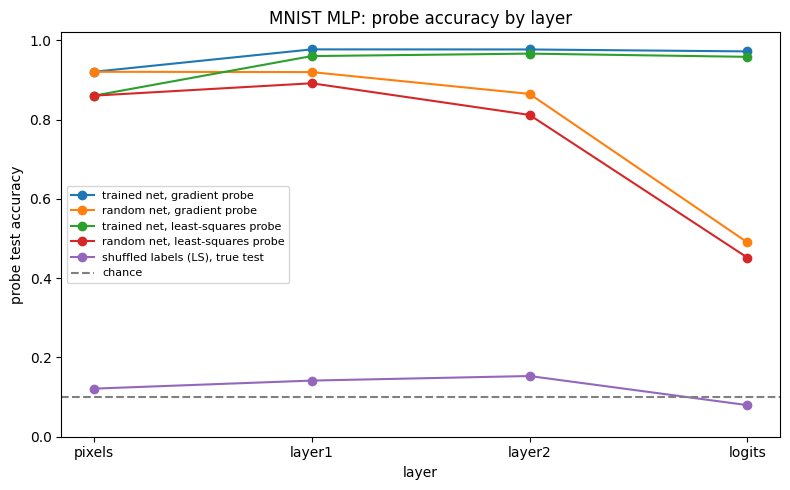

  layer | GD trained  GD random  GD gain |  LS gain
 pixels |      0.920      0.920   +0.000 |   +0.000
 layer1 |      0.977      0.920   +0.057 |   +0.069
 layer2 |      0.977      0.865   +0.112 |   +0.155
 logits |      0.972      0.490   +0.482 |   +0.506


In [32]:
# Gradient probe on trained and random nets (so the controls use the same probe as the headline numbers)
gd_trained = {n: probe_acc(train_probe(acts_train[n], y_train, 10), acts_test[n], y_test) for n in layers}
gd_random  = {n: probe_acc(train_probe(rand_train[n], y_train, 10), rand_test[n], y_test) for n in layers}

curves = {
    "trained net, gradient probe":      [gd_trained[n] for n in layers],
    "random net, gradient probe":       [gd_random[n] for n in layers],
    "trained net, least-squares probe": [results[n][0] for n in layers],
    "random net, least-squares probe":  [results[n][1] for n in layers],
    "shuffled labels (LS), true test":  [results[n][3] for n in layers],
}
plot_probe_curves(curves, layers, title="MNIST MLP: probe accuracy by layer")

print(f"{'layer':>7} | {'GD trained':>10} {'GD random':>10} {'GD gain':>8} | {'LS gain':>8}")
for n in layers:
    print(f"{n:>7} | {gd_trained[n]:>10.3f} {gd_random[n]:>10.3f} {gd_trained[n] - gd_random[n]:>+8.3f} | {results[n][0] - results[n][1]:>+8.3f}")